In [1]:
from pydicom import dcmread
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import skimage as ski 

In [2]:
src = Path('data/FBIRN_QA_FMRI_FLIP77_0014')
dcmfiles = [dcmread(p) for p in sorted(src.glob('*.dcm'))]

In [3]:
def unmosaic(dcm):
    return np.stack([col for row in np.split(dcm.pixel_array.astype(float),6) for col in np.split(row,6,axis=1)])

img = np.stack([unmosaic(d) for d in dcmfiles])
img.shape

ValueError: need at least one array to stack

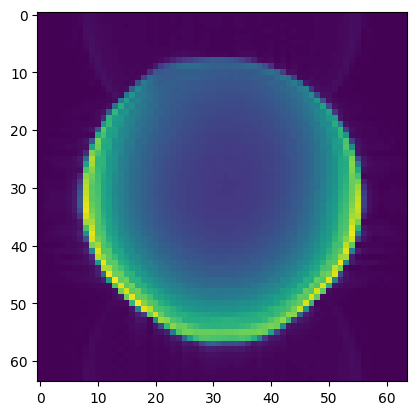

In [143]:
plt.imshow(img[0,12,:,:])

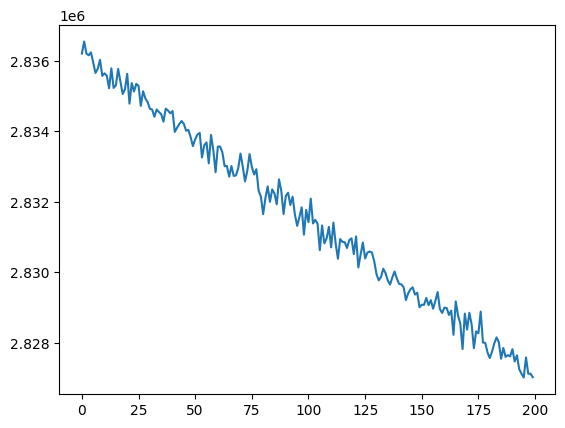

In [144]:
plt.plot(img[:,12,:,:].sum(axis=2).sum(axis=1))

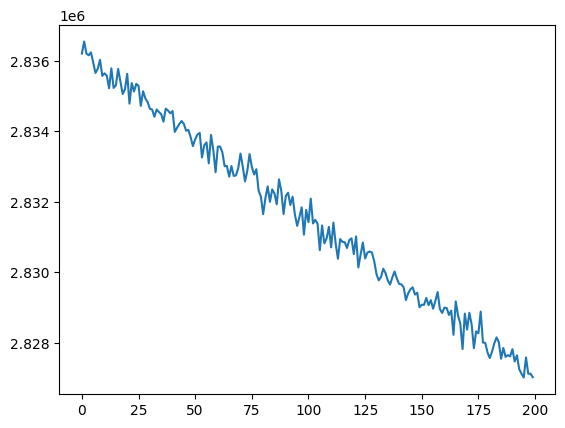

In [145]:
plt.plot(img[:,12,:,:].sum(axis=2).sum(axis=1))

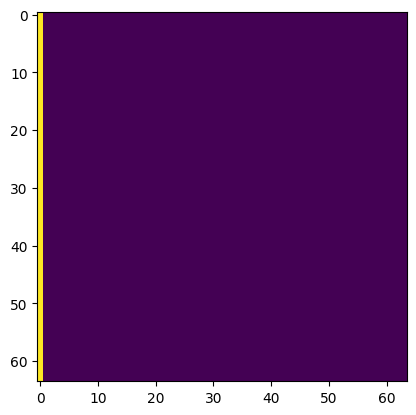

In [146]:
m = img.std(axis=0)
plt.imshow(img[0,12,:,:] == 0)

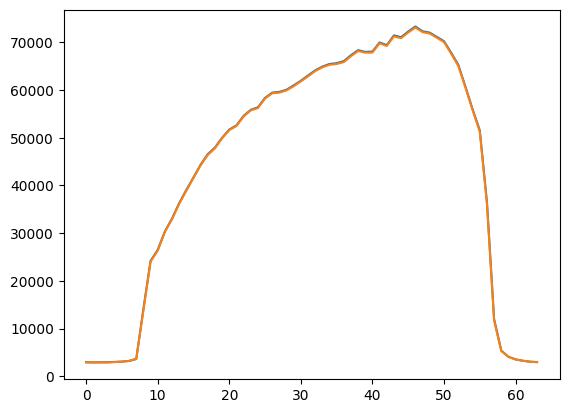

In [147]:
k1 = img[0,12,:,:]
plt.plot(k1.sum(axis=1))

k2 = img[-1,12,:,:]
plt.plot(k2.sum(axis=1))

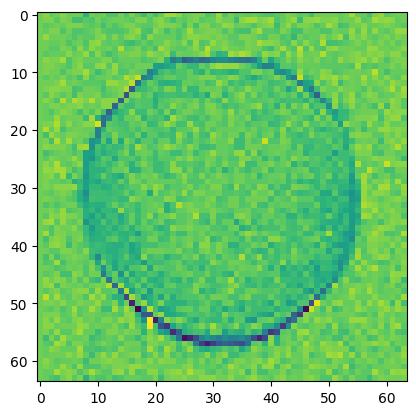

In [148]:
plt.imshow(k2-k1)

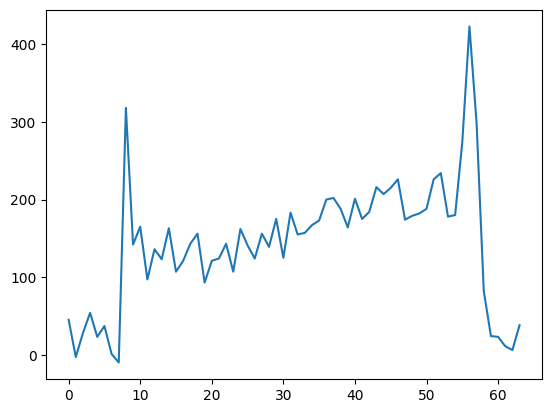

In [149]:
plt.plot(k1.sum(axis=1) - k2.sum(axis=1))

In [150]:
np.fft.fft(k1.sum(axis=1))[0]

np.complex128(2836208+0j)

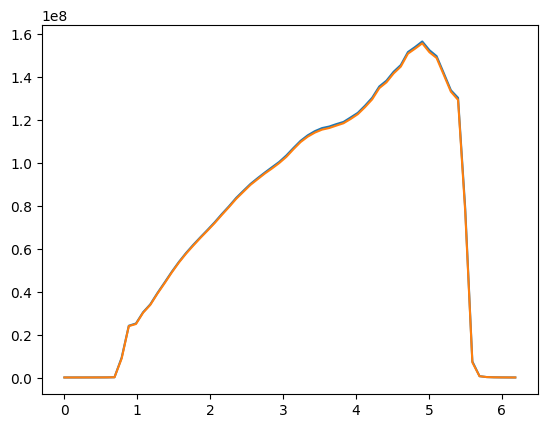

In [151]:
p1 = np.power(k1,2).sum(axis=1)
p2 = np.power(k2,2).sum(axis=1)
t = np.linspace(0, 2*np.pi, len(p1)+1)[:-1]

plt.plot(t, p1)
plt.plot(t, p2)

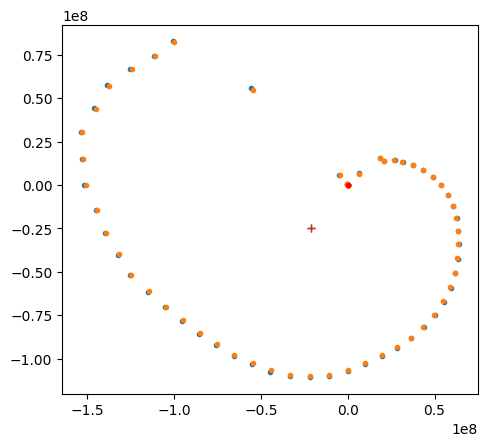

In [152]:
p3 = p2-p1
#plt.plot(p3*np.sin(t), p3*np.cos(t), '.')
plt.plot(p1*np.sin(t), p1*np.cos(t), '.')
plt.plot(p2*np.sin(t), p2*np.cos(t), '.')
plt.plot(0, 0, 'r.')
plt.plot((p1*np.sin(t)).mean(), (p1*np.cos(t)).mean(), '+')
plt.plot((p2*np.sin(t)).mean(), (p2*np.cos(t)).mean(), '+')

plt.gca().set_aspect('equal', 'box')

(200, 64)

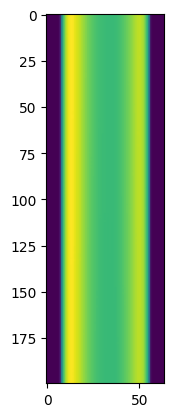

In [162]:
p = np.power(img,2).sum(axis=1).sum(axis=1)
plt.imshow(p)
p.shape

In [163]:
dt = 2*np.pi/64
t = dt*np.arange(64)
t.shape

(64,)

np.float64(-14.272992233955696)

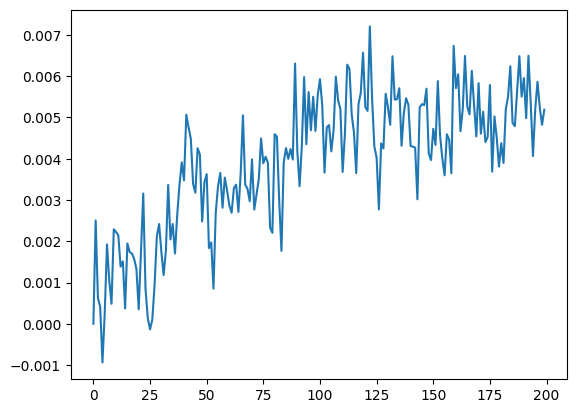

In [164]:
dx = np.atan2(np.mean(p * np.cos(t), axis=1), np.mean(p * np.sin(t), axis=1))/dt
plt.plot(dx-dx[0])
dx[0]
#plt.ylim([-16,-14])

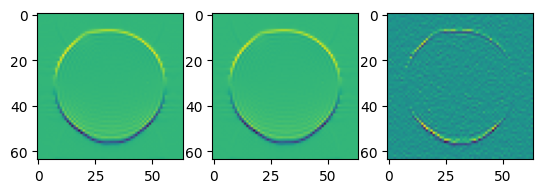

In [207]:
def cdiff(img, *, axis=0):
    return np.diff(img, append=img[None,:,-1], axis=0)

fig, ax = plt.subplots(1, 3)
i1 = img[0,12,:,:]
i2 = img[-1,12,:,:]
e1 = cdiff(i1)
e2 = cdiff(i2)
ax[0].imshow(e1)
ax[1].imshow(e2)
ax[2].imshow(e1-e2)

592
591.0
591.0
591.0
591.0
591.0


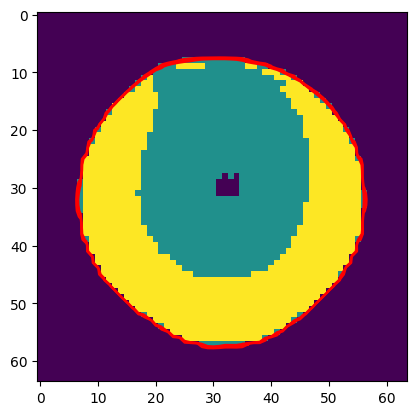

In [351]:
def cummax_sym_2d(img):
    return np.minimum(
        np.minimum(
            np.maximum.accumulate(img, axis=1),
            np.maximum.accumulate(img[:,::-1], axis=1)[:,::-1],
        ),
        np.minimum(
            np.maximum.accumulate(img, axis=0),
            np.maximum.accumulate(img[::-1,:], axis=0)[::-1,:],
        )
    )

def convex_contour(image, thr):
    return sorted(ski.measure.find_contours(image, thr), key=len, reverse=True)[0]

def get_contour(img, f=1.0):
    w1 = cummax_sym_2d(img)
    thr = ski.filters.threshold_otsu(w1)
    return sorted(ski.measure.find_contours(w1, f*thr), key=len, reverse=True)[0]

from scipy import ndimage as ndi


def acr_threshold(img):
    img = np.asarray(img).astype(int)
    y = img.size - np.cumsum(np.bincount(img.ravel()))
    p2 = y[1::2]
    p1 = y[0 : p2.size]
    thr = np.where(p1 - p2 < p2)[0][-1]
    for i in range(4):
        print(thr)
        mask = ndi.binary_fill_holes(img > thr, np.ones((3, 3)))
        thr = 0.5*np.median(img[mask])
    return thr
    
plt.imshow(i1, 'gray')
w1 = cummax_sym_2d(i1)
thr = acr_threshold(i1)
print(thr)

plt.imshow((i1>thr).astype(int) + (i1 > 2*thr))
print(thr)
for f in [0.75, 1.0, 1.25]:
    contour = convex_contour(i1, f*thr)
    plt.plot(contour[:,1], contour[:,0], 'r')

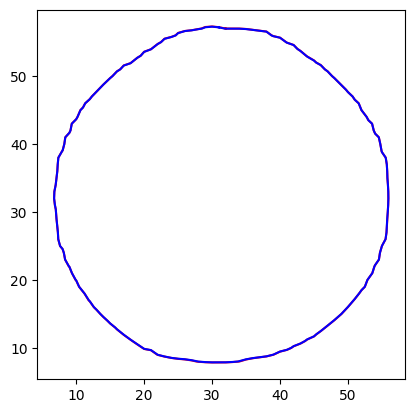

In [272]:
contour1 = get_contour(i1)
contour2 = get_contour(i2)
plt.plot(contour1[:,1], contour1[:,0], 'r-')
plt.plot(contour2[:,1], contour2[:,0], 'b-')


In [280]:
contour1[:,1] contour1[:,0])

TypeError: only length-1 arrays can be converted to Python scalars

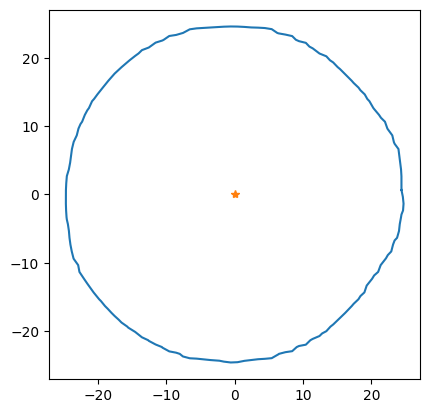

In [297]:
x, y = np.hsplit(contour1,2)
x0 = 0.5*(x.min()+x.max())
y0 = 0.5*(y.min()+y.max())
z = (x-x0).astype(complex)
z.imag = y-y0

plt.plot(z.real, z.imag)
plt.plot(0,0,"*")
plt.gca().set_aspect('equal', 'box')

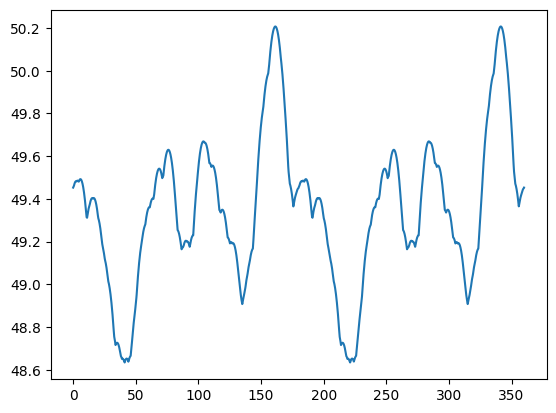

In [312]:
theta = np.linspace(0,2*np.pi,10000)
r = (z*np.exp(1j*theta)).real

plt.plot(180*theta/np.pi, r.max(axis=0)-r.min(axis=0))

In [309]:
np.linspace(0, 1, 10)

array([0.        , 0.11111111, 0.22222222, 0.33333333, 0.44444444,
       0.55555556, 0.66666667, 0.77777778, 0.88888889, 1.        ])

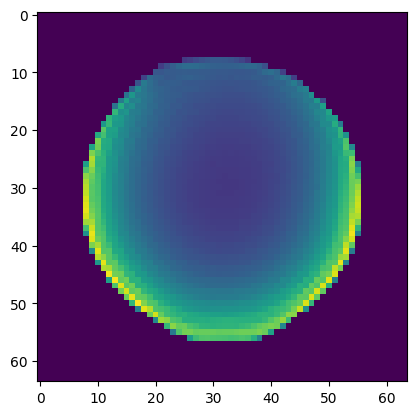

In [360]:
thr = ski.filters.threshold_local(i1, 13)
mask = ndi.binary_fill_holes(i1 > thr, np.ones((3, 3)))
mask = ski.morphology.remove_small_objects(mask)
plt.imshow(i1 * mask)

In [368]:
import nibabel.nicom.csareader as csar

In [370]:
csar.get_csa_header(dcmfiles[0])

{'tags': {'EchoLinePosition': {'n_items': 6,
   'vm': 1,
   'vr': 'IS',
   'syngodt': 6,
   'last3': 77,
   'tag_no': 0,
   'items': [32]},
  'EchoColumnPosition': {'n_items': 6,
   'vm': 1,
   'vr': 'IS',
   'syngodt': 6,
   'last3': 77,
   'tag_no': 1,
   'items': [32]},
  'EchoPartitionPosition': {'n_items': 6,
   'vm': 1,
   'vr': 'IS',
   'syngodt': 6,
   'last3': 77,
   'tag_no': 2,
   'items': [32]},
  'UsedChannelMask': {'n_items': 0,
   'vm': 1,
   'vr': 'UL',
   'syngodt': 9,
   'last3': 205,
   'tag_no': 3,
   'items': []},
  'UsedChannelString': {'n_items': 6,
   'vm': 1,
   'vr': 'UT',
   'syngodt': 27,
   'last3': 77,
   'tag_no': 4,
   'items': ['XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX']},
  'Actual3DImaPartNumber': {'n_items': 0,
   'vm': 1,
   'vr': 'IS',
   'syngodt': 6,
   'last3': 205,
   'tag_no': 5,
   'items': []},
  'ICE_Dims': {'n_items': 6,
   'vm': 1,
   'vr': 'LO',
   'syngodt': 19,
   'last3': 77,
   'tag_no': 6,
   'items': ['X_1_1_1_1_1_1_16_